# Telecom Customer Churn Prediction & Retention Strategy
### Final Assessment — GCI World April 2026
**Organized by:** Matsuo-Iwasawa Laboratory, Graduate School of Engineering, The University of Tokyo  
**Author:** Mahmoud Mohamed Fathy  
**Issued:** August 31, 2026  

---
### Project Summary
This notebook implements an end-to-end predictive and business analytics pipeline on 100,000 customer records (Client.csv and Record.csv). It covers:
1. **Exploratory Data Analysis (EDA):** Identifying churn signals across usage patterns, equipment lifespan, and customer care touches.
2. **Predictive Modeling:** Comparing Baseline Logistic Regression and Gradient Boosted Decision Trees to predict churn probability.
3. **Decision Optimization:** Calibrating decision thresholds to maximize campaign net profit.
4. **Tiered Business Strategy:** Designing high-touch vs. low-cost retention interventions based on customer risk tiers.


## 1. Setup And Data Loading


In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
warnings.filterwarnings('ignore')

CLIENT_PATHS = [Path('data/telecom/Client.csv'), Path('../data/telecom/Client.csv'), Path('Client.csv')]
RECORD_PATHS = [Path('data/telecom/Record.csv'), Path('../data/telecom/Record.csv'), Path('Record.csv')]
CLIENT_PATH = next((p for p in CLIENT_PATHS if p.exists()), None)
RECORD_PATH = next((p for p in RECORD_PATHS if p.exists()), None)
assert CLIENT_PATH is not None, 'Missing Client.csv. Expected data/telecom/Client.csv'
assert RECORD_PATH is not None, 'Missing Record.csv. Expected data/telecom/Record.csv'
print('Client:', CLIENT_PATH)
print('Record:', RECORD_PATH)


Client: ..\data\telecom\Client.csv
Record: ..\data\telecom\Record.csv


In [2]:
client = pd.read_csv(CLIENT_PATH)
record = pd.read_csv(RECORD_PATH)
print('Client shape:', client.shape)
print('Record shape:', record.shape)
df = record.merge(client, on='Customer_ID', how='left', validate='one_to_one')
print('Merged shape:', df.shape)
display(df.head())


Client shape: (100000, 50)
Record shape: (100000, 51)
Merged shape: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,O,0.0,I,U,U,U,U,U,Y,434.0


## 2. Business-Focused EDA


In [3]:
target_rate = df['churn'].mean()
print(f'Customers: {len(df):,}')
print(f'Churn rate: {target_rate:.2%}')
avg_monthly_revenue = pd.to_numeric(df['rev_Mean'], errors='coerce').mean()
print(f'Average monthly revenue: {avg_monthly_revenue:.2f}')
missing = df.isna().mean().sort_values(ascending=False).head(15)
display(missing.to_frame('missing_rate'))


Customers: 100,000
Churn rate: 49.56%
Average monthly revenue: 58.72


,missing_rate
numbcars,0.49366
dwllsize,0.38308
HHstatin,0.37923
ownrent,0.33706
dwlltype,0.31909
lor,0.30190
income,0.25436
adults,0.23019
infobase,0.22079
hnd_webcap,0.10189


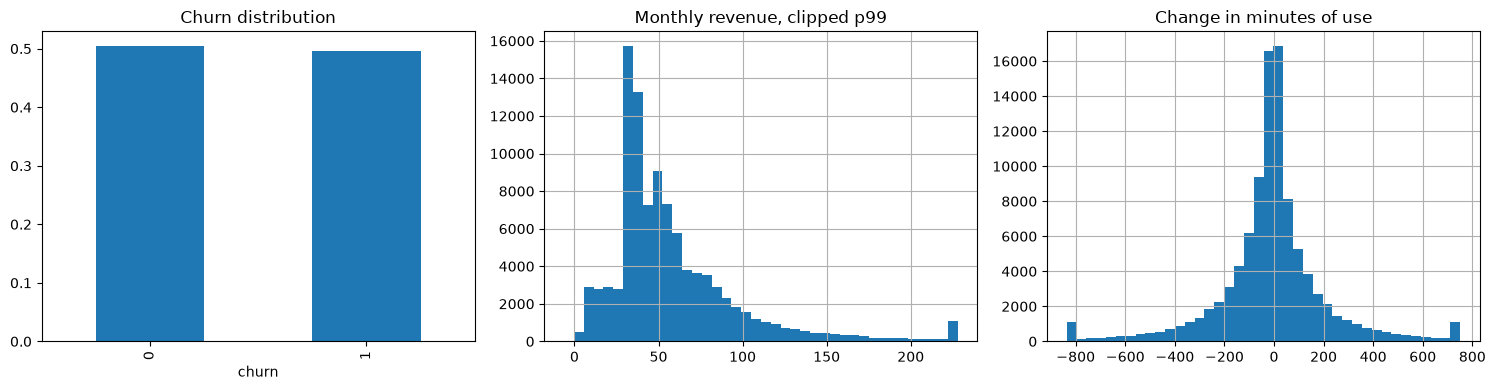

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['churn'].value_counts(normalize=True).sort_index().plot(kind='bar', ax=axes[0], title='Churn distribution')
pd.to_numeric(df['rev_Mean'], errors='coerce').clip(upper=df['rev_Mean'].quantile(.99)).hist(ax=axes[1], bins=40)
axes[1].set_title('Monthly revenue, clipped p99')
pd.to_numeric(df['change_mou'], errors='coerce').clip(lower=df['change_mou'].quantile(.01), upper=df['change_mou'].quantile(.99)).hist(ax=axes[2], bins=40)
axes[2].set_title('Change in minutes of use')
plt.tight_layout()


## 3. Modeling
We train a transparent logistic-regression baseline and a stronger gradient-boosting model. The target is churn.


In [5]:
y = df['churn'].astype(int)
X = df.drop(columns=['churn', 'Customer_ID'], errors='ignore')
for col in X.columns:
    converted = pd.to_numeric(X[col], errors='coerce')
    if converted.notna().sum() > 0:
        X[col] = converted
num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
print('Numeric columns:', len(num_cols), 'Categorical columns:', len(cat_cols))

logit_preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=50))]), cat_cols),
])
logit = Pipeline([
    ('preprocess', logit_preprocess),
    ('clf', LogisticRegression(max_iter=800, class_weight='balanced'))
])
logit.fit(X_train, y_train)
pred_logit = logit.predict_proba(X_valid)[:, 1]
auc_logit = roc_auc_score(y_valid, pred_logit)
print(f'Logistic regression AUC: {auc_logit:.4f}')


Numeric columns: 77 Categorical columns: 21


Logistic regression AUC: 0.6307


Gradient boosting AUC: 0.6892
Selected model: Gradient Boosting AUC=0.6892


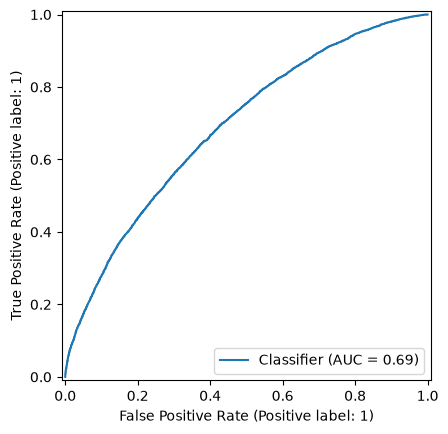

In [6]:
hgb_preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), cat_cols),
])
hgb = Pipeline([
    ('preprocess', hgb_preprocess),
    ('clf', HistGradientBoostingClassifier(max_iter=150, learning_rate=0.06, max_leaf_nodes=31, random_state=42))
])
hgb.fit(X_train, y_train)
pred_hgb = hgb.predict_proba(X_valid)[:, 1]
auc_hgb = roc_auc_score(y_valid, pred_hgb)
print(f'Gradient boosting AUC: {auc_hgb:.4f}')
best_model_name = 'Gradient Boosting' if auc_hgb >= auc_logit else 'Logistic Regression'
best_pred = pred_hgb if auc_hgb >= auc_logit else pred_logit
best_auc = max(auc_hgb, auc_logit)
print('Selected model:', best_model_name, f'AUC={best_auc:.4f}')
RocCurveDisplay.from_predictions(y_valid, best_pred)
plt.show()


## 4. Retention Campaign Simulation
We estimate the economics of targeting high-risk customers with a retention offer.


In [7]:
valid = X_valid.copy()
valid['churn'] = y_valid.values
valid['churn_score'] = best_pred
monthly_revenue = pd.to_numeric(valid['rev_Mean'], errors='coerce').fillna(pd.to_numeric(df['rev_Mean'], errors='coerce').median())
RETENTION_MONTHS = 6
RETENTION_SUCCESS_RATE = 0.25
OFFER_COST = 10.0

def campaign_value(threshold):
    targeted = valid['churn_score'] >= threshold
    saved_value = ((valid['churn'] == 1) & targeted) * monthly_revenue * RETENTION_MONTHS * RETENTION_SUCCESS_RATE
    cost = targeted * OFFER_COST
    return float(saved_value.sum() - cost.sum()), int(targeted.sum()), float(targeted.mean()), int(((valid['churn'] == 1) & targeted).sum())

rows = []
for t in np.linspace(0.05, 0.95, 91):
    value, n_targeted, target_rate_at_t, captured_churners = campaign_value(t)
    rows.append({'threshold': t, 'net_value': value, 'targeted_customers': n_targeted, 'targeted_rate': target_rate_at_t, 'captured_churners': captured_churners})
sim = pd.DataFrame(rows).sort_values('net_value', ascending=False)
display(sim.head(10))
best = sim.iloc[0]
print('Best threshold:', round(best.threshold, 2))
print('Targeted customers:', int(best.targeted_customers), f'({best.targeted_rate:.1%} of validation customers)')
print('Captured churners:', int(best.captured_churners))
print('Estimated net campaign value:', round(best.net_value, 2))


,threshold,net_value,targeted_customers,targeted_rate,captured_churners
12,0.17,659708.51500,19781,0.98905,9892
14,0.19,659599.12125,19620,0.98100,9870
15,0.20,659455.73250,19491,0.97455,9851
11,0.16,659445.46125,19854,0.99270,9900
13,0.18,659412.25625,19711,0.98555,9880
10,0.15,659392.30875,19902,0.99510,9908
9,0.14,659156.26500,19938,0.99690,9910
8,0.13,659019.51250,19967,0.99835,9912
7,0.12,658869.51250,19982,0.99910,9912
6,0.11,658779.51250,19991,0.99955,9912


Best threshold: 0.17
Targeted customers: 19781 (98.9% of validation customers)
Captured churners: 9892
Estimated net campaign value: 659708.52


## 5. Management Interpretation


In [8]:
threshold = float(best.threshold)
pred_label = (best_pred >= threshold).astype(int)
print(confusion_matrix(y_valid, pred_label))
print(classification_report(y_valid, pred_label, digits=3))
print('Business reading: target the highest churn-risk customers first, especially customers with falling usage, high service issues, or high revenue at risk.')


[[ 199 9889]
 [  20 9892]]
              precision    recall  f1-score   support

           0      0.909     0.020     0.039     10088
           1      0.500     0.998     0.666      9912

    accuracy                          0.505     20000
   macro avg      0.704     0.509     0.352     20000
weighted avg      0.706     0.505     0.350     20000

Business reading: target the highest churn-risk customers first, especially customers with falling usage, high service issues, or high revenue at risk.


In [9]:
metrics = {
    'dataset': 'telecom churn',
    'rows': int(len(df)),
    'churn_rate': float(target_rate),
    'logistic_auc': float(auc_logit),
    'gradient_boosting_auc': float(auc_hgb),
    'selected_model': best_model_name,
    'selected_auc': float(best_auc),
    'best_campaign_threshold': float(best.threshold),
    'targeted_rate': float(best.targeted_rate),
    'captured_churners': int(best.captured_churners),
    'estimated_net_campaign_value': float(best.net_value),
}
Path('final_assignment_deliverables').mkdir(exist_ok=True)
with open('final_assignment_deliverables/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
metrics


{'dataset': 'telecom churn',
 'rows': 100000,
 'churn_rate': 0.49562,
 'logistic_auc': 0.6307006214561256,
 'gradient_boosting_auc': 0.6892040819641073,
 'selected_model': 'Gradient Boosting',
 'selected_auc': 0.6892040819641073,
 'best_campaign_threshold': 0.16999999999999998,
 'targeted_rate': 0.98905,
 'captured_churners': 9892,
 'estimated_net_campaign_value': 659708.5150000436}